In [21]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis,QuadraticDiscriminantAnalysis
import matplotlib.pyplot as plt
import seaborn as sns
import os
os.chdir('E:/Machine_Learning/Datasets/')

In [3]:
df = pd.read_csv('iris.csv')
df.head()

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [9]:
X,y = df.drop('Species',axis = 1),df['Species']
lda = LinearDiscriminantAnalysis().set_output(transform = 'pandas')
X_lda= lda.fit_transform(X,y)
lda_data = pd.concat([X_lda,y],axis = 1)
lda_data
# Number of components(reduced features) (<= min(n_classes - 1, n_features)) for dimensionality reduction. 
# If None, will be set to min(n_classes - 1, n_features). This parameter only affects the transform method.

,lineardiscriminantanalysis0,lineardiscriminantanalysis1,Species
0,8.143648,-0.303471,setosa
1,7.201062,0.794647,setosa
2,7.565869,0.268079,setosa
3,6.882372,0.677440,setosa
4,8.214873,-0.519686,setosa
...,...,...,...
145,-5.702315,-1.694750,virginica
146,-5.232150,0.367165,virginica
147,-5.018176,-0.829477,virginica
148,-5.945905,-2.368899,virginica


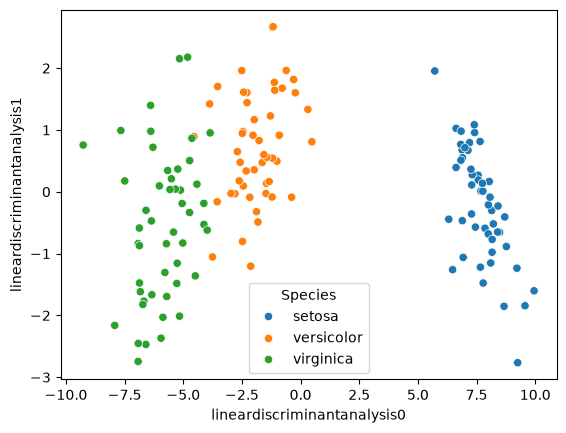

In [18]:
sns.scatterplot(data = lda_data,x = 'lineardiscriminantanalysis0',y = 'lineardiscriminantanalysis1',hue='Species')
plt.show()

In [ ]:
## Sepal.Length 	Sepal.Width	  Petal.Length	 Petal.Width

### so in the lda data graph we can see similar pattern and also we can discriminate (classify) the clusters correctly .. so we can use those 2 features as new features (reduced)

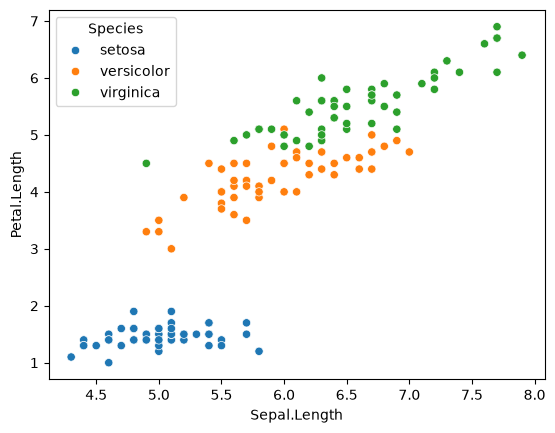

In [20]:
sns.scatterplot(data = df , x = 'Sepal.Length',y = 'Petal.Length',hue = 'Species')
plt.show()

## Apply the KNN on normla data and lda data both and see difference

In [26]:
# on original data
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

df = pd.read_csv('iris.csv')
X,y = df.drop('Species',axis = 1),df['Species']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [28]:
scaler = StandardScaler()
ks = np.arange(1,16)
scores = []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    pipe = Pipeline([('SCL',scaler),('KNN',knn)])
    pipe.fit(X_train,y_train)
    y_pred = pipe.predict(X_test)
    scores.append([k,accuracy_score(y_test,y_pred)])

df_sc = pd.DataFrame(scores,columns=['k','accuracy'])
df_sc.sort_values(by=['accuracy'],ascending=False)

,k,accuracy
0,1,0.955556
4,5,0.955556
12,13,0.955556
9,10,0.933333
13,14,0.933333
10,11,0.933333
5,6,0.933333
14,15,0.933333
6,7,0.911111
2,3,0.911111


In [29]:
lda_data

,lineardiscriminantanalysis0,lineardiscriminantanalysis1,Species
0,8.143648,-0.303471,setosa
1,7.201062,0.794647,setosa
2,7.565869,0.268079,setosa
3,6.882372,0.677440,setosa
4,8.214873,-0.519686,setosa
...,...,...,...
145,-5.702315,-1.694750,virginica
146,-5.232150,0.367165,virginica
147,-5.018176,-0.829477,virginica
148,-5.945905,-2.368899,virginica


In [30]:
X,y = lda_data.drop('Species',axis = 1),df['Species']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [31]:
scaler = StandardScaler()
ks = np.arange(1,16)
scores = []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    pipe = Pipeline([('SCL',scaler),('KNN',knn)])
    pipe.fit(X_train,y_train)
    y_pred = pipe.predict(X_test)
    scores.append([k,accuracy_score(y_test,y_pred)])

df_sc = pd.DataFrame(scores,columns=['k','accuracy'])
df_sc.sort_values(by=['accuracy'],ascending=False)

,k,accuracy
0,1,1.000000
1,2,0.955556
2,3,0.955556
3,4,0.955556
5,6,0.955556
8,9,0.955556
7,8,0.955556
11,12,0.955556
12,13,0.955556
9,10,0.955556
